In [168]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

df = pd.read_csv('berita_warta_nusa.csv')
display(df.head())

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,id_artikel,tanggal,sumber,isi_artikel,rubrik
0,AR001,2026-07-15,Warta Nusa,Cakra Data meluncurkan dompet digital terbaru ...,teknologi
1,AR002,2026-09-22,Kabar Bangsa,Atlet Lestari Wulandari meraih medali emas cab...,olahraga
2,AR003,2026-09-09,Kabar Bangsa,Federasi bulu tangkis Indonesia menyiapkan pem...,olahraga
3,AR004,2026-07-25,Kabar Bangsa,pertandingan yang disaksikan 21.000 penonton i...,olahraga
4,AR005,2026-08-13,Warta Nusa,pt bumi sentosa membukukan laba bersih rp487 m...,ekonomi


In [169]:
x = df['isi_artikel']
y = df['rubrik']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Jumlah data latih: {len(x_train)} | Jumlah data uji: {len(x_test)}')

Jumlah data latih: 72 | Jumlah data uji: 18


In [170]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()
stop_words = set(stopwords.words('indonesian'))

def preprocess_text(text):
    text = str(text).lower()

    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)

    tokens = word_tokenize(text)

    filtered_tokens = [w for w in tokens if w not in stop_words]
    stemmed_tokens =[stemmer.stem(w) for w in filtered_tokens]
    
    return ' '.join(stemmed_tokens)

x_train_clean = x_train.apply(preprocess_text)
x_test_clean = x_test.apply(preprocess_text)

perbandingan = ({
    'Data Latih Asli': x_train,
    'Data Latih Prep': x_train_clean,
    'Data Uji Asli': x_test,
    'Data Uji Prep': x_test_clean,
})

display(perbandingan)

{'Data Latih Asli': 26    Bank Indonesia mempertahankan suku bunga acuan...
 40    Harga nikel di pasar domestik bergerak naik se...
 50    Menurut Fajar Nugroho, kepala riset Cakra Data...
 60    Pemerintah menyiapkan insentif pajak untuk men...
 62    Pelatih Rina Setiawati mengaku puas dengan pen...
                             ...                        
 27    Atlet Dewi Kartika meraih medali emas cabang a...
 73    JARINGAN 5G DITARGETKAN MENJANGKAU 6 KOTA DI I...
 15    Persada Jaya berhasil mengalahkan Kencana FC d...
 84    Pemerintah menyiapkan insentif pajak untuk men...
 21    Pembaruan sistem terbaru menghadirkan fitur ke...
 Name: isi_artikel, Length: 72, dtype: str,
 'Data Latih Prep': 26    bank indonesia tahan suku bunga acu level pers...
 40    harga nikel pasar domestik gerak laku usaha se...
 50    fajar nugroho kepala riset cakra data teknolog...
 60    perintah insentif pajak dorong investasi tumbu...
 62    latih rina setiawati aku puas tampil main lini...
      

In [171]:
vectorizer = TfidfVectorizer()
x_train_tfidf = vectorizer.fit_transform(x_train_clean)
x_test_tfidf = vectorizer.transform(x_test_clean)

print('Dimensi matriks latih:', x_train_tfidf.shape)
print('Dimensi matriks uji:', x_test_tfidf.shape)

Dimensi matriks latih: (72, 262)
Dimensi matriks uji: (18, 262)


In [172]:
query = 'berita teknologi terbaru Indonesia'

def preprocess_query(query):
    query = str(query).lower()
    query = re.sub(r'http\S+|www\.\S+', '', query)
    query = re.sub(r'\d+', '', query)
    query = re.sub(r'[^\w\s]', ' ', query)
    query = re.sub(r'\s+', ' ', query)

    tokens = word_tokenize(query)

    filtered_tokens = [w for w in tokens if w not in stop_words]
    stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]
    
    return ' '.join(stemmed_tokens)

query_clean = [preprocess_query(query)]
query_tfidf = vectorizer.transform(query_clean)
similarity = cosine_similarity(query_tfidf, x_train_tfidf)

df_similarity = pd.DataFrame(
    similarity, 
    index=['Query'], 
    columns=[f'Doc {i+1}' for i in range(x_train_tfidf.shape[0])]
)

display(df_similarity)

,Doc 1,Doc 2,Doc 3,Doc 4,Doc 5,Doc 6,Doc 7,Doc 8,Doc 9,Doc 10,...,Doc 63,Doc 64,Doc 65,Doc 66,Doc 67,Doc 68,Doc 69,Doc 70,Doc 71,Doc 72
Query,0.050216,0.04471,0.335298,0.02306,0.037023,0.03824,0.202479,0.024677,0.0,0.440352,...,0.027374,0.024566,0.0,0.057081,0.029775,0.0,0.152622,0.0,0.056877,0.352307


In [173]:
similarity = cosine_similarity(x_train_tfidf[:3], x_train_tfidf[:3])
df_similarity = pd.DataFrame(similarity, index=[f'Doc {i+1}' for i in range(3)], columns=[f'Doc {i+1}' for i in range(3)])

print('Matriks Cosine Similarity (3 Dokumen Pertama):')
display(df_similarity.round(3))

Matriks Cosine Similarity (3 Dokumen Pertama):


,Doc 1,Doc 2,Doc 3
Doc 1,1.000,0.513,0.017
Doc 2,0.513,1.000,0.015
Doc 3,0.017,0.015,1.000


In [174]:
mnb = MultinomialNB()

mnb.fit(x_train_tfidf, y_train)
y_pred = mnb.predict(x_test_tfidf)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     ekonomi       1.00      1.00      1.00         6
    olahraga       1.00      1.00      1.00         6
   teknologi       1.00      1.00      1.00         6

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



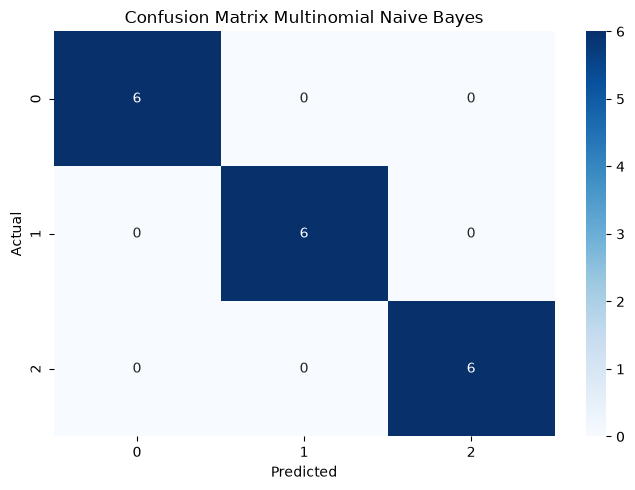

In [175]:
fig, axes = plt.subplots(1, 1, figsize=(7, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes)
axes.set_title('Confusion Matrix Multinomial Naive Bayes')
axes.set_xlabel('Predicted')
axes.set_ylabel('Actual')
plt.tight_layout()
plt.show()